# CART Models: Employee Analytics Prediction

This notebook uses a **synthetic employee dataset with 10,000 records**.

- **Classification:** Predict `Attrition` (Yes/No) using a CART Decision Tree Classifier and Gini impurity.
- **Regression:** Predict `Monthly_Salary` using a CART Decision Tree Regressor and squared error.
- The dataset is created for learning and does not represent real employees or a real company.

**Important:** `Monthly_Salary` is excluded from the attrition model, and `Attrition` is excluded from the salary model.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the dataset
Keep `employee_analytics_cart_dataset.csv` in the same folder as this notebook.

In [2]:
df = pd.read_csv("employee_analytics_cart_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 17)


,Age,Experience_Years,Department,Job_Level,Education,Remote_Work,Overtime,Job_Satisfaction,Work_Life_Balance,Projects_Count,Training_Hours,Promotion_Last_2_Years,Commute_Minutes,Company_Tenure_Years,Performance_Rating,Monthly_Salary,Attrition
0,24,0,Operations,Junior,Master,Yes,Yes,4,4,1,3,No,59,0,Good,18491,Yes
1,51,28,Operations,Lead,PhD,No,Yes,5,1,7,2,No,39,13,Average,59424,No
2,47,21,IT,Lead,Bachelor,No,Yes,3,1,1,6,No,2,5,Good,61960,No
3,38,11,IT,Senior,Bachelor,Yes,Yes,3,1,6,6,No,8,10,Average,35993,No
4,38,15,Sales,Senior,Bachelor,Yes,No,1,4,1,2,No,41,11,Excellent,52408,No


## 3. Explore the dataset

In [3]:
df.info()
print("\\nMissing values:")
display(df.isnull().sum())
print("\\nAttrition distribution:")
display(df["Attrition"].value_counts())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Age                     10000 non-null  int64
 1   Experience_Years        10000 non-null  int64
 2   Department              10000 non-null  str  
 3   Job_Level               10000 non-null  str  
 4   Education               10000 non-null  str  
 5   Remote_Work             10000 non-null  str  
 6   Overtime                10000 non-null  str  
 7   Job_Satisfaction        10000 non-null  int64
 8   Work_Life_Balance       10000 non-null  int64
 9   Projects_Count          10000 non-null  int64
 10  Training_Hours          10000 non-null  int64
 11  Promotion_Last_2_Years  10000 non-null  str  
 12  Commute_Minutes         10000 non-null  int64
 13  Company_Tenure_Years    10000 non-null  int64
 14  Performance_Rating      10000 non-null  str  
 15  Monthly_Salary          10000 n

Age                       0
Experience_Years          0
Department                0
Job_Level                 0
Education                 0
Remote_Work               0
Overtime                  0
Job_Satisfaction          0
Work_Life_Balance         0
Projects_Count            0
Training_Hours            0
Promotion_Last_2_Years    0
Commute_Minutes           0
Company_Tenure_Years      0
Performance_Rating        0
Monthly_Salary            0
Attrition                 0
dtype: int64

\nAttrition distribution:


Attrition
No     6945
Yes    3055
Name: count, dtype: int64

,Age,Experience_Years,Job_Satisfaction,Work_Life_Balance,Projects_Count,Training_Hours,Commute_Minutes,Company_Tenure_Years,Monthly_Salary
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,40.352000,15.276700,3.006700,3.012100,4.519900,4.000000,30.375500,5.581300,40791.86690
std,11.490809,11.214469,1.413455,1.420336,2.288302,2.578617,17.227001,4.654778,18781.82939
min,21.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,18000.00000
25%,30.000000,5.000000,2.000000,2.000000,3.000000,2.000000,16.000000,1.000000,20264.75000
50%,40.000000,15.000000,3.000000,3.000000,5.000000,4.000000,30.000000,5.000000,39423.50000
75%,50.000000,25.000000,4.000000,4.000000,7.000000,6.000000,45.000000,9.000000,59042.25000
max,60.000000,38.000000,5.000000,5.000000,8.000000,8.000000,60.000000,15.000000,81683.00000


## 4. Basic preprocessing

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

Missing values: 0
Duplicate rows: 0
Duplicate rows: 0


## 5. Exploratory data analysis

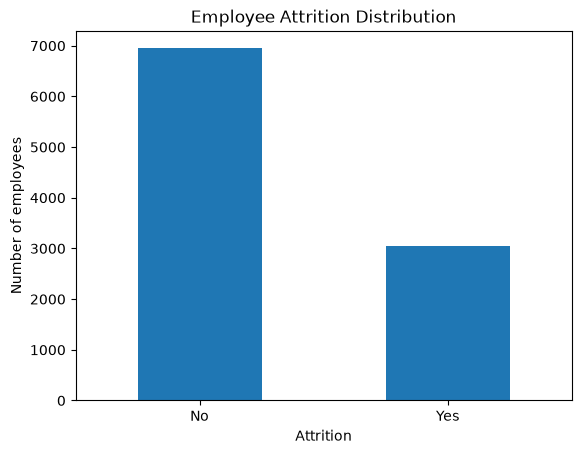

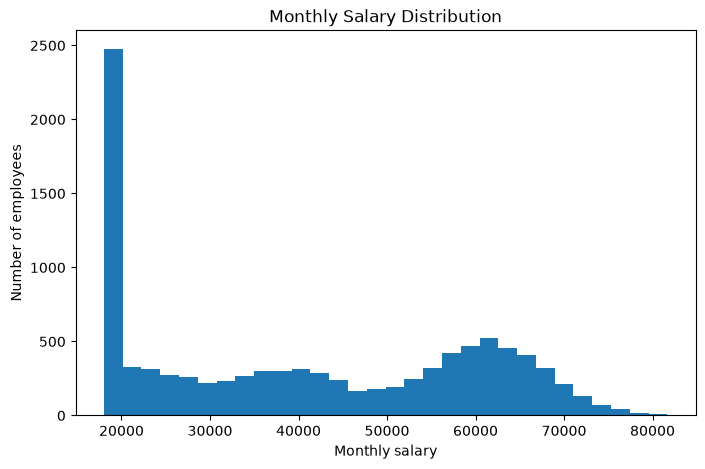

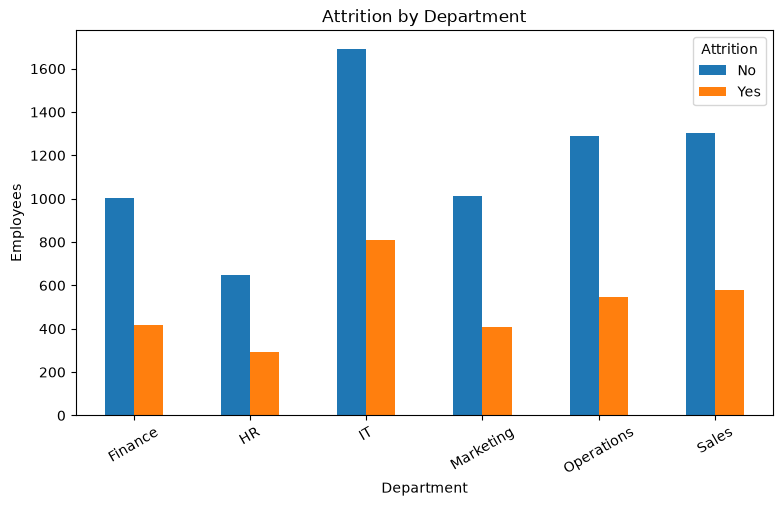

In [5]:
df["Attrition"].value_counts().plot(kind="bar")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of employees")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df["Monthly_Salary"], bins=30)
plt.title("Monthly Salary Distribution")
plt.xlabel("Monthly salary")
plt.ylabel("Number of employees")
plt.show()

pd.crosstab(df["Department"], df["Attrition"]).plot(kind="bar", figsize=(9,5))
plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Employees")
plt.xticks(rotation=30)
plt.show()

# Part A: CART Classification

## 6. Select features and target

We predict whether an employee leaves the company. We exclude `Monthly_Salary` from the inputs to keep the classification task focused on employee and work-related factors.

In [6]:
features = [
    "Age", "Experience_Years", "Department", "Job_Level", "Education",
    "Remote_Work", "Overtime", "Job_Satisfaction", "Work_Life_Balance",
    "Projects_Count", "Training_Hours", "Promotion_Last_2_Years",
    "Commute_Minutes", "Company_Tenure_Years", "Performance_Rating"
]
X = df[features]
y = df["Attrition"]

categorical = [
    "Department", "Job_Level", "Education", "Remote_Work", "Overtime",
    "Promotion_Last_2_Years", "Performance_Rating"
]
numeric = [
    "Age", "Experience_Years", "Job_Satisfaction", "Work_Life_Balance",
    "Projects_Count", "Training_Hours", "Commute_Minutes", "Company_Tenure_Years"
]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", "passthrough", numeric)
])

## 7. Split into training and testing sets

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


## 8. Build and train the CART classifier

`criterion="gini"` uses Gini impurity to choose splits. `max_depth` and `min_samples_leaf` help control overfitting.

In [8]:
cart_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="gini", max_depth=6, min_samples_leaf=10, random_state=42
    ))
])
cart_classifier.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Experience_Years','Department',...,'Commute_Minutes', 'Company_Tenure_Years','Performance_Rating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'d

## 9. Predict and evaluate classification

In [9]:
y_pred = cart_classifier.predict(X_test)
display(pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head(15))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

,Actual,Predicted
0,No,No
1,No,No
2,No,No
3,Yes,Yes
4,Yes,No
5,Yes,No
6,No,No
7,No,No
8,No,No
9,No,No


Accuracy: 0.688
\nConfusion matrix:
[[1284  105]
 [ 519   92]]
\nClassification report:
              precision    recall  f1-score   support

          No       0.71      0.92      0.80      1389
         Yes       0.47      0.15      0.23       611

    accuracy                           0.69      2000
   macro avg       0.59      0.54      0.52      2000
weighted avg       0.64      0.69      0.63      2000



## 10. Visualize the classification tree

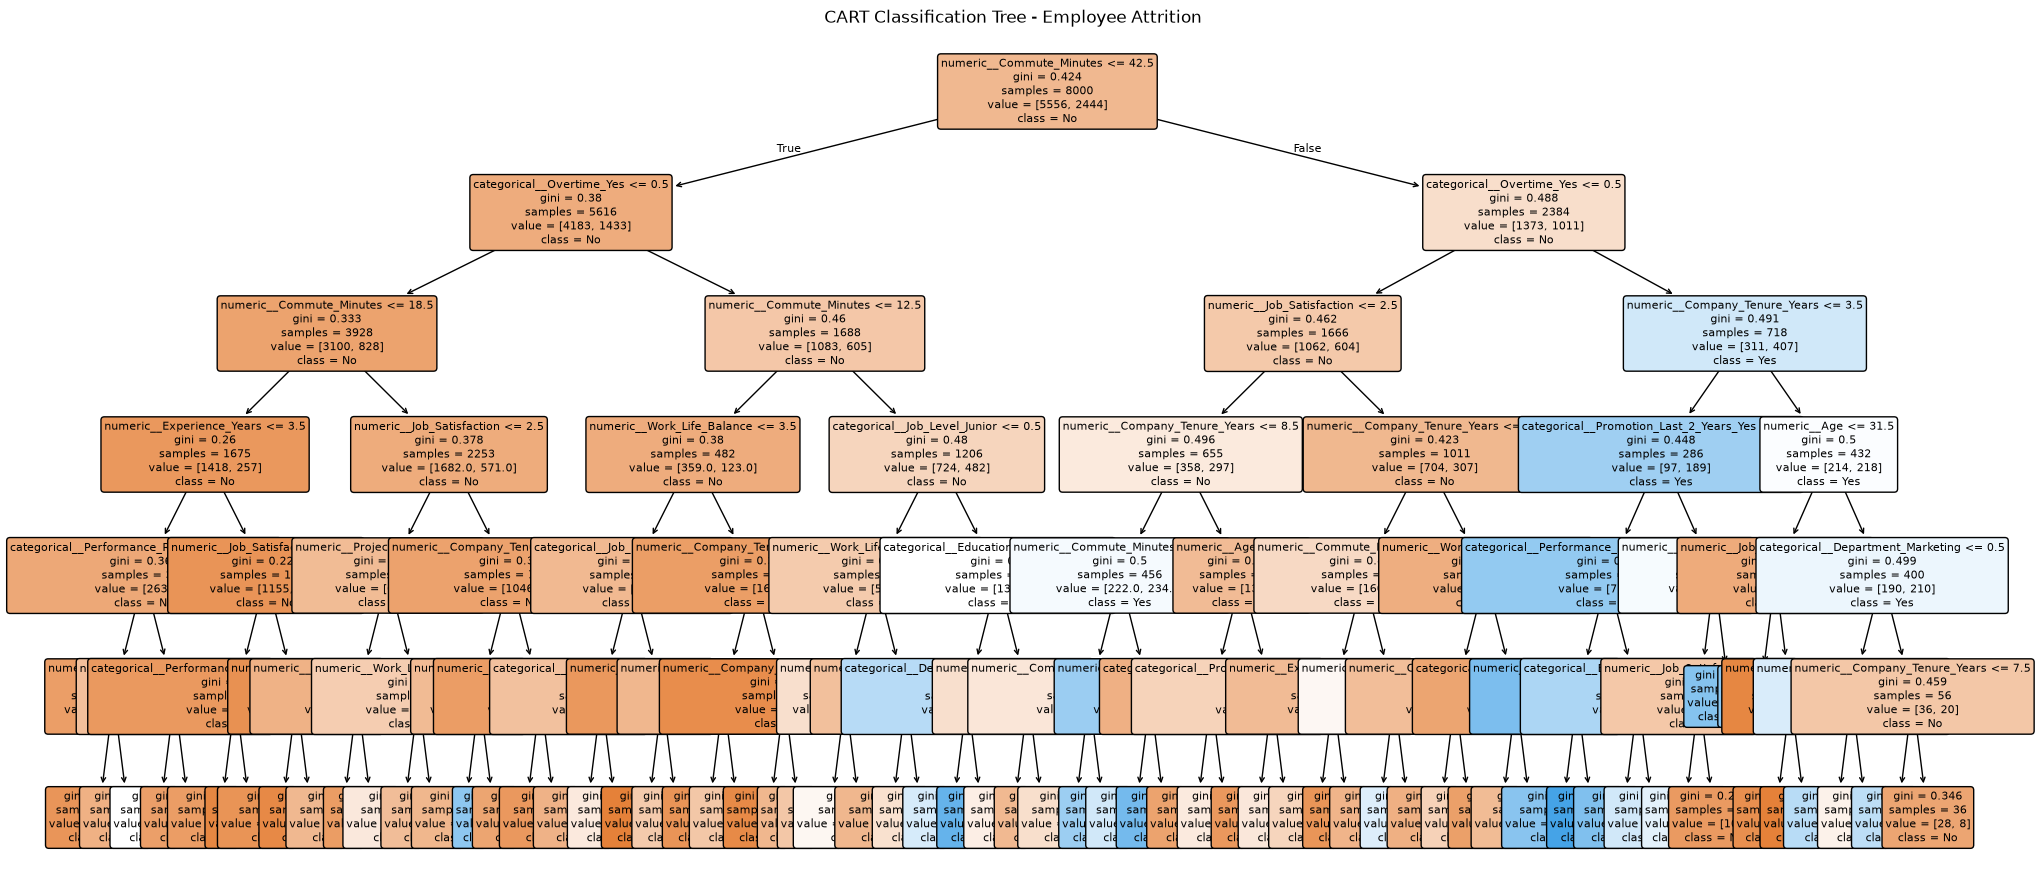

In [10]:
classifier_features = cart_classifier.named_steps["preprocessor"].get_feature_names_out()
classifier_tree = cart_classifier.named_steps["model"]

plt.figure(figsize=(24, 11))
plot_tree(classifier_tree, feature_names=classifier_features,
          class_names=classifier_tree.classes_, filled=True,
          rounded=True, fontsize=8)
plt.title("CART Classification Tree - Employee Attrition")
plt.show()

## 11. Classification feature importance

numeric__Commute_Minutes         0.329798
categorical__Overtime_Yes        0.210193
numeric__Job_Satisfaction        0.109817
numeric__Company_Tenure_Years    0.105679
numeric__Work_Life_Balance       0.037477
numeric__Age                     0.034033
numeric__Experience_Years        0.031896
numeric__Projects_Count          0.030555
numeric__Training_Hours          0.018586
categorical__Job_Level_Junior    0.016074
dtype: float64

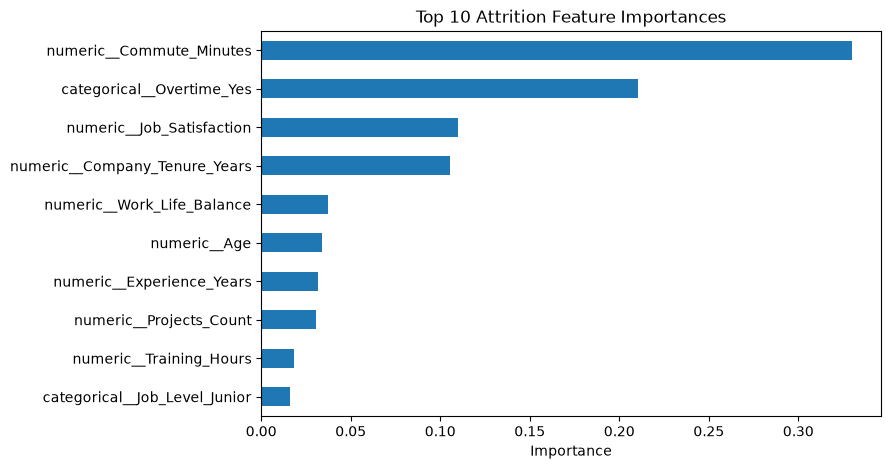

In [11]:
importance = pd.Series(
    classifier_tree.feature_importances_, index=classifier_features
).sort_values(ascending=False)

display(importance.head(10))
importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Attrition Feature Importances")
plt.xlabel("Importance")
plt.show()

# Part B: CART Regression

## 12. Select regression features and target

The regression model predicts monthly salary. We exclude both target columns (`Monthly_Salary` and `Attrition`) from the input features.

In [12]:
reg_features = [
    "Age", "Experience_Years", "Department", "Job_Level", "Education",
    "Remote_Work", "Overtime", "Job_Satisfaction", "Work_Life_Balance",
    "Projects_Count", "Training_Hours", "Promotion_Last_2_Years",
    "Commute_Minutes", "Company_Tenure_Years", "Performance_Rating"
]
X_reg = df[reg_features]
y_reg = df["Monthly_Salary"]

regression_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", "passthrough", numeric)
])

## 13. Split regression data

In [13]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
print("Training rows:", len(X_reg_train))
print("Testing rows:", len(X_reg_test))

Training rows: 8000
Testing rows: 2000


## 14. Build and train the CART regressor

For regression, CART selects splits that reduce the squared error of the predicted numeric values.

In [14]:
cart_regressor = Pipeline([
    ("preprocessor", regression_preprocessor),
    ("model", DecisionTreeRegressor(
        criterion="squared_error", max_depth=6,
        min_samples_leaf=10, random_state=42
    ))
])
cart_regressor.fit(X_reg_train, y_reg_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Age','Experience_Years','Department',...,'Commute_Minutes', 'Company_Tenure_Years','Performance_Rating']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be autom

## 15. Predict and evaluate regression

In [15]:
y_reg_pred = cart_regressor.predict(X_reg_test)
display(pd.DataFrame({
    "Actual Salary": y_reg_test.values,
    "Predicted Salary": y_reg_pred.round(0).astype(int)
}).head(15))

mse = mean_squared_error(y_reg_test, y_reg_pred)
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred))
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2 Score:", r2_score(y_reg_test, y_reg_pred))

,Actual Salary,Predicted Salary
0,18000,20137
1,29480,38043
2,63444,62978
3,37361,39248
4,54945,42645
5,18000,18602
6,56959,63240
7,60379,62978
8,20551,18088
9,31704,39772


MAE: 3142.3347606307484
MSE: 18408928.722444173
RMSE: 4290.56275125352
R2 Score: 0.948157632829983


## 16. Visualize the regression tree

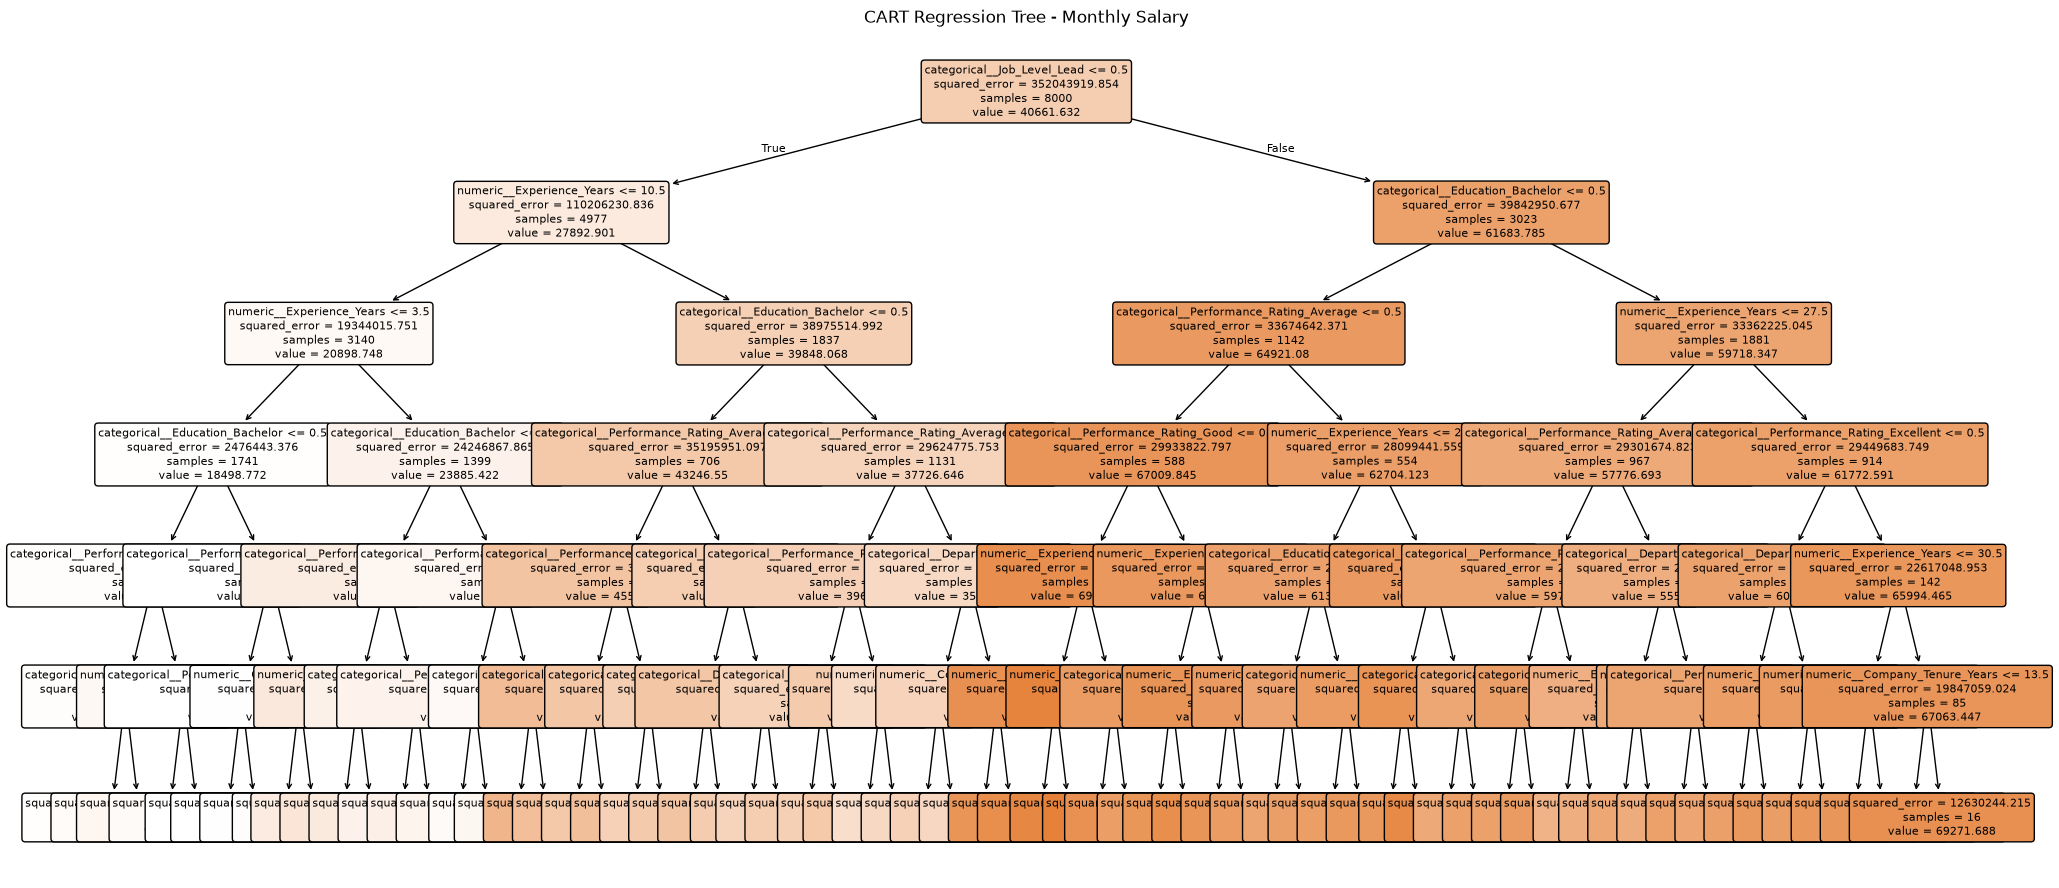

In [16]:
regression_features = cart_regressor.named_steps["preprocessor"].get_feature_names_out()
regression_tree = cart_regressor.named_steps["model"]

plt.figure(figsize=(24, 11))
plot_tree(regression_tree, feature_names=regression_features,
          filled=True, rounded=True, fontsize=8)
plt.title("CART Regression Tree - Monthly Salary")
plt.show()

## 17. Actual vs predicted monthly salary

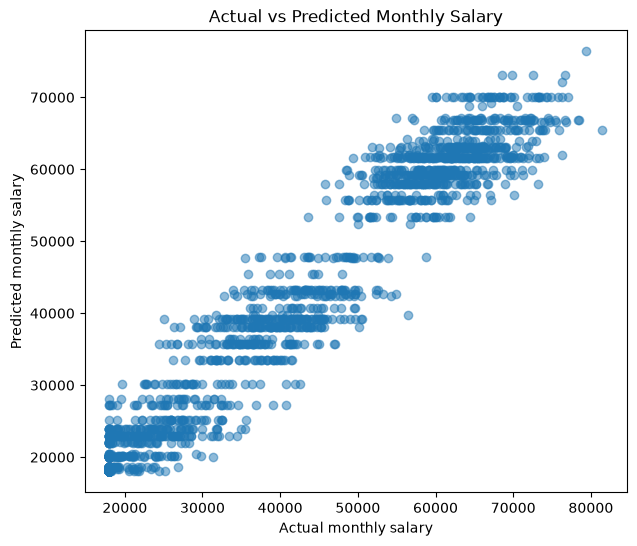

In [17]:
plt.figure(figsize=(7, 6))
plt.scatter(y_reg_test, y_reg_pred, alpha=0.5)
plt.xlabel("Actual monthly salary")
plt.ylabel("Predicted monthly salary")
plt.title("Actual vs Predicted Monthly Salary")
plt.show()

## 18. Predict for a new employee

In [18]:
new_employee = pd.DataFrame([{
    "Age": 29,
    "Experience_Years": 6,
    "Department": "IT",
    "Job_Level": "Mid",
    "Education": "Bachelor",
    "Remote_Work": "Yes",
    "Overtime": "No",
    "Job_Satisfaction": 4,
    "Work_Life_Balance": 3,
    "Projects_Count": 4,
    "Training_Hours": 5,
    "Promotion_Last_2_Years": "No",
    "Commute_Minutes": 20,
    "Company_Tenure_Years": 4,
    "Performance_Rating": "Good"
}])

print("Predicted attrition:", cart_classifier.predict(new_employee)[0])
print("Predicted monthly salary:",
      round(cart_regressor.predict(new_employee)[0], 0))

Predicted attrition: No
Predicted monthly salary: 23000.0


## 19. CART: Classification vs Regression

| Aspect | Classification | Regression |
|---|---|---|
| Target | Attrition (Yes/No) | Monthly_Salary |
| Model | DecisionTreeClassifier | DecisionTreeRegressor |
| Split criterion | Gini impurity | Squared error (MSE) |
| Output | Category | Number |
| Metrics | Accuracy, precision, recall, F1 | MAE, MSE, RMSE, R² |

## Key takeaways

- CART stands for **Classification and Regression Trees**.
- CART creates binary splits in the feature space.
- Classification predicts a category; regression predicts a numeric value.
- One-hot encoding converts categorical input features into numeric columns.
- The dataset is synthetic learning data, not real employee data.

**Practice:** Change `max_depth` to 3, 5, 8, and `None`. Compare test metrics and observe overfitting.